## Fairness Audit

## Objectives 
- Compare default rates across age groups and home ownership 
- Train a default prediction model and assess whether it treats groups fairly 
- Visualise the finding for teh README and Power BI dashboard

## Inputs 
- data/processed/credit_risk_fairness.csv

## Outputs 
- Fairness charts and tables 
- data/processed/fairness_results.csv (Power BI) 


In [3]:
#import os so we can work with folders 
import os 

if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

#print current folder 
print(os.getcwd())

c:\Users\mezen\OneDrive\Documents\Tech\Simple_Project_Template\ethical-credit-risk-analysis


In [4]:
#import libraries for diagrams
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

#load prepared dataset from notebook 01
df = pd.read_csv("data/processed/credit_risk_fairness.csv")

#confirm shape 
print(df.shape)

(32409, 15)


## Default rates by Age Group 
- This checks whether certain age groups default more often than others with this data. 
- A difference in default rate may not automatically suggest unfairness, but with modelling it could determine whether certain age groups get refused credit more often than others. 

In [5]:
#overall default rate across all borrowers as a percentage 
overall_rate = df["loan_status"].mean() * 100
print(f"Overall default rate: {overall_rate:.1f}%")

#number of borrowers and default rate for each age group 
#shows proportion of borrowers in each age group that defaulted 
age_summary = df.groupby("age_group").agg(
    borrowers=("loan_status", "count"),
    default_rate=("loan_status", "mean")
)

#turn default rate into percentage 
age_summary["default_rate"] = (age_summary["default_rate"] * 100).round(1)

#display table
age_summary 

Overall default rate: 21.9%


,borrowers,default_rate
age_group,,
20-24,12220,23.3
25-29,11142,21.4
30-39,7291,20.2
40+,1756,21.3


In [6]:
#set chart size 
plt.figure(figsize=(8, 5))

#bar chart showing default rate for each age group 
sns.barplot(data=age_summary.reset_index(), x="age_group", y="default_rate", color="steelblue")

#line showing overall default rate for comparison 
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")

#labels for titles and axis 
plt.title("Default rate by age group")
plt.xlabel("Age group")
plt.ylabel("Default rate (%)")
plt.legend()

#save chart as image for README
plt.savefig("images/default_rate_by_age_group.png", bbox_inches="tight")

#show chart
plt.show()

<Figure size 800x500 with 1 Axes>

## Observations
- The overall default rate is 21.9%
- Default rates are similar across age groups, peaking at 20-24 with 23.3% with a low of 20.2% at ages 30-39. 
- The younger groups default more often, which may reflect lower incomes and shorter credit histories rather than age alone. 

## Default rates by Home Ownership
- Home ownership is not a protected characteristic, but it can act as an indication of wealth and background. Using it in lending decisions could indirectly disadvantage groups less likely to own homes, such as younger people. 

In [7]:
#number of borrowers and default rate for each home ownership type 
home_summary = df.groupby("person_home_ownership").agg(
    borrowers=("loan_status", "count"),
    default_rate=("loan_status", "mean")
)
#change default rate into percentage 
home_summary["default_rate"] = (home_summary["default_rate"] * 100).round(1)

#sort default rate from highest to lowest 
home_summary = home_summary.sort_values("default_rate", ascending=False)

#show table 
home_summary

,borrowers,default_rate
person_home_ownership,,
RENT,16374,31.6
OTHER,106,31.1
MORTGAGE,13366,12.6
OWN,2563,7.5


## Observations 
- Renters have the highest default rate at 31.6%, over 4x that of homeowners at 7.5%.
- The "OTHER" group has 106 borrowers which is too small to draw conclusions from. 
- Home ownership is a much stromger predictor of default than age. Because of this a model will likely rely on it heavily, which could indirectly disadvantage groups less likely to own homes, such as young people. 

In [8]:
#show how home ownership is spread across age groups 
home_by_age = (pd.crosstab(df["age_group"], df["person_home_ownership"], normalize="index") *100).round(1)

#show table
home_by_age 

person_home_ownership,MORTGAGE,OTHER,OWN,RENT
age_group,,,,
20-24,38.0,0.4,8.2,53.4
25-29,42.8,0.3,7.6,49.3
30-39,43.7,0.1,7.9,48.3
40+,43.7,0.5,7.7,48.1


## Observations 
- Renting is most common among 20-24 year older and falls slightlt with age
- Home ownership is similar across all age groups at around 8% 
- The is a link between age and homeownership, though modest. A model that relies on homeownership will disadvantage renters of all ages but mostly younger people.

## 03 Model Fairness Check 
A regression model is used to predict default without age. It also exludes loan_grade and loan_int_rate, which are the lenders own risk judgements. The models predictions will then be compared across age groups to test whther removign age group is enough to make the test fair. 

In [10]:
#import tools to build and test model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score, classification_report#

#number columns for model 
numeric_features = ["person_income", "person_emp_length", "loan_amnt",
                   "loan_percent_income", "cb_person_cred_hist_length"]

#text columns used by model
categorical_features = ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]

#X is the information the model learns from, y is what it predicts (1= default)
X = df[numeric_features + categorical_features]
y = df["loan_status"] 

#split into 80% training and 20% testing data 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

#prepare data 
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

#combine preperation and model into one pipeline
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

#train model on training data 
model.fit(X_train, y_train)

#predict default for test data
y_pred = model.predict(X_test)

#show how well model performs
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))



Accuracy: 0.837
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      5064
           1       0.73      0.40      0.52      1418

    accuracy                           0.84      6482
   macro avg       0.79      0.68      0.71      6482
weighted avg       0.83      0.84      0.82      6482



## Model performance 
- Accuracy is 83%, compared with 78% for a basleine that always predicts no default 
- However, recall shows us the model only catches 40% of borrowers who actually default 

## 04 Fairness metrics by group 
For each group the models test predictions will be compared using: 
- Flagged rate: % of borrowers the model predicts will default 
- Approval rate: % predicted not to default 
- False positive rate: % of borrowers who did not default but were wrongly flagged
- True positive rate: % of actual defaulters correctly flagged 
- Approval ratio: each group's approval rate divided by the highest groups

In [13]:
#combine the test data with actual outcomes and the model's predictions
results = X_test.copy()

#bring back age_group from the full dataset 
results["age_group"] = df.loc[X_test.index, "age_group"]
results["actual"] = y_test
results["predicted"] = y_pred

def fairness_table(data, group_col):
    """""Calculate fairness metrics for each group in_col."""
    rows = []
    #loop through each group 
    for group, g in data.groupby(group_col):
        #borrowers who did not default / did default
        non_defaulters = g[g["actual"] == 0]
        defaulters = g[g["actual"] == 1]
        rows.append({
            "attribute": group_col,
            "group": group,
            "borrowers": len(g),
            "actual_default_rate": g["actual"].mean() * 100,
            "flagged_rate": g["predicted"].mean() * 100,
            "approval_rate": (1 - g["predicted"].mean()) * 100,
            "false_positive_rate": non_defaulters["predicted"].mean() * 100,
            "true_positive_rate": defaulters["predicted"].mean() * 100,
        })
    table = pd.DataFrame(rows)
    #Approval ratio compared with the best-treated group (four-fifths rule)
    table["approval_ratio"] = table["approval_rate"] / table["approval_rate"].max()
    return table.round(2)

#Fairness metrics by age group and home ownership 
age_fairness = fairness_table(results, "age_group")
home_fairness = fairness_table(results, "person_home_ownership")

#show tables 
display(age_fairness)
display(home_fairness)

#save tables for the dashboard 
fairness_results = pd.concat([age_fairness, home_fairness])
fairness_results.to_csv("data/processed/fairness_results.csv", index=False)

,attribute,group,borrowers,actual_default_rate,flagged_rate,approval_rate,false_positive_rate,true_positive_rate,approval_ratio
0,age_group,20-24,2380,22.77,13.24,86.76,3.70,45.57,0.95
1,age_group,25-29,2257,22.42,11.92,88.08,4.40,37.94,0.97
2,age_group,30-39,1470,20.07,11.16,88.84,4.68,36.95,0.98
3,age_group,40+,375,20.00,9.07,90.93,3.00,33.33,1.00


,attribute,group,borrowers,actual_default_rate,flagged_rate,approval_rate,false_positive_rate,true_positive_rate,approval_ratio
0,person_home_ownership,MORTGAGE,2651,12.94,3.39,96.61,2.56,9.04,0.98
1,person_home_ownership,OTHER,23,21.74,13.04,86.96,0.00,60.00,0.88
2,person_home_ownership,OWN,533,7.88,1.13,98.87,0.41,9.52,1.00
3,person_home_ownership,RENT,3275,31.39,20.85,79.15,6.59,52.04,0.80


## Observations 
Age:
- The model does not include age s a characterstic, but still flags younger borrowers more often. 13.2% of 20-24 year older compared with 9.1% of 40+ year olds, even though their actual default rates are similar 
- It also catches fewer defaulters aged 40+, 33.3%  vs 45.6% for 20-24 year olds, so it is less reliable for older borrowers who are under-represented in the data. 
- All age groups pass the four-fifths rule (approval ratios 0.95-1.00) so age bias isn't large. It used indirect features linkd to age such as income, credit history length and home ownership. 
- Removing age did not make the model fully fair. 

Home ownership:
- Renters are approved 79.2% of the time compared with 98.9% for home owners. 
- Among the borrowers who did not default, 6.6% of renters were wrongly flagged compared with 0.4% of homeowners, suggesting that credit worthy renters are much more likely to be unfairly refused. 
- The "OTHER" category is too small a sample size to draw conclusions from. 

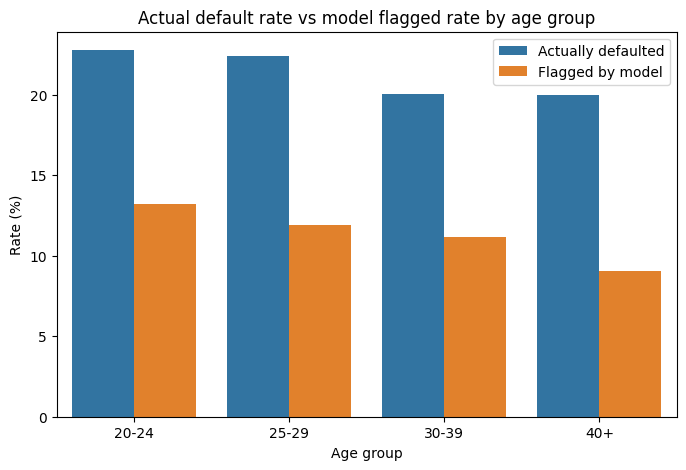

In [15]:
#shape the age table for actual and flagged rates 
age_chart = age_fairness.melt(
    id_vars="group",
    value_vars=["actual_default_rate", "flagged_rate"],
    var_name="measure",
    value_name="rate"
)
#give the measures names
age_chart["measure"] = age_chart["measure"].replace({
    "actual_default_rate": "Actually defaulted",
    "flagged_rate": "Flagged by model"
})

#group bar chart comparing reality with model predictions
plt.figure(figsize=(8, 5))
sns.barplot(data=age_chart, x="group", y="rate", hue="measure")

#titles and labels
plt.title("Actual default rate vs model flagged rate by age group")
plt.xlabel("Age group")
plt.ylabel("Rate (%)")
plt.legend(title="")

#save for README
plt.savefig("images/actual_vs_flagged_by_age.png", bbox_inches="tight")
plt.show()

## Conclusions
- Actual default rates differ little by age but strongly by home ownership. 
- A model trained without age still flage younger borrowers more often and is less accurate for older borrowers, showing that removing a protected characteristic does not remove bias. 
- Seemingly, home ownership drives the largest disparity. Creditworthy renters are far more likely to be wrongly refused and renters also sit exactly on the four-fifths threshold.
- A recommendation would be to monitor approval and false positve rates by group and to review whether hoem wonership should be used 